In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words=open("names.txt","r").read().splitlines()

In [3]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
stoi={s:i+1 for i,s in enumerate(sorted(set(''.join(words))))}
stoi['.']=0
itos={i:s for s,i in stoi.items()}

In [5]:
block_size=4
X,Y=[],[]
for w in words:
    
    content=[0]*block_size
    for ch in w+'.':
        ix=stoi[ch]
        X.append(content)
        Y.append(ix)
        content=content[1:]+[ix]
X=torch.tensor(X)
Y=torch.tensor(Y)

In [6]:
def datasets(words):
    block_size=4
    X,Y=[],[]
    for w in words:
        
        content=[0]*block_size
        for ch in w+'.':
            ix=stoi[ch]
            X.append(content)
            Y.append(ix)
            content=content[1:]+[ix]
    X=torch.tensor(X)
    Y=torch.tensor(Y)
    print(X.shape,Y.shape)
    return X,Y

In [7]:
import random
random.seed(42)
random.shuffle(words)
n1=int(0.8*(len(words)))
n2=int(0.9*(len(words)))
Xtr,Ytr=datasets(words[:n1])
Xdev,Ydev=datasets(words[n1:n2])
Xtest,Ytest=datasets(words[n2:])

torch.Size([182625, 4]) torch.Size([182625])
torch.Size([22655, 4]) torch.Size([22655])
torch.Size([22866, 4]) torch.Size([22866])


In [8]:
Xtr.shape,Ytr.shape

(torch.Size([182625, 4]), torch.Size([182625]))

In [9]:
g=torch.Generator().manual_seed(2147483647)
C=torch.randn((27,13),generator=g)
W1=torch.randn((52,200),generator=g)
b1=torch.randn(200,generator=g)
W2=torch.randn((200,27),generator=g)
b2=torch.randn(27,generator=g)
parameters=[C,W1,W2,b1,b2]

In [10]:
lre=torch.linspace(-3,0,1000)
lrs=10**lre

In [11]:
for p in parameters:
    p.requires_grad=True

In [12]:
lrsi=[]
lossi=[]
stepi=[]

In [13]:

for i in range(200000):
    ix=torch.randint(0,Xtr.shape[0],(64,))
    emd=C[Xtr[ix]]
    h=torch.tanh(emd.view(-1,52)@W1+b1)
    logits=h@W2+b2
    loss=F.cross_entropy(logits,Ytr[ix])
    for p in parameters:
        p.grad=None
    loss.backward()
    lr=0.1 if i<100000 else 0.01
    for p in parameters:
        p.data+=-lr*p.grad
    lossi.append(loss.item())
    stepi.append(i)


In [14]:
emd=C[Xtr]
h=torch.tanh(emd.view(-1,52)@W1+b1)
logits=h@W2+b2
loss=F.cross_entropy(logits,Ytr)
loss

tensor(2.1100, grad_fn=<NllLossBackward0>)

In [15]:

emd=C[Xdev]
h=torch.tanh(emd.view(-1,52)@W1+b1)
logits=h@W2+b2
loss=F.cross_entropy(logits,Ydev)
loss

tensor(2.1564, grad_fn=<NllLossBackward0>)

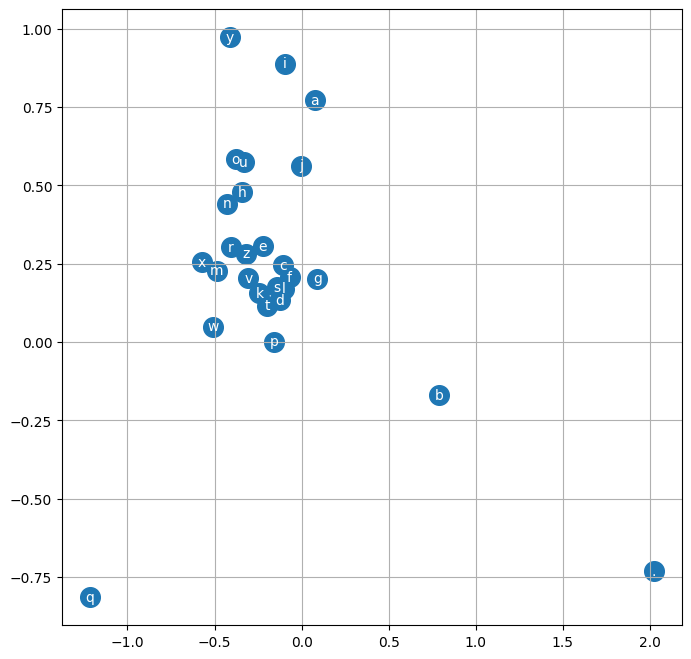

In [16]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data,C[:,1].data,s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(),C[i,1].item(),itos[i],ha="center",va="center",color="white")
plt.grid('minor')

In [17]:
g=torch.Generator().manual_seed(2147483647+10)
blocksize=4
for _ in range(20):
    content=[0]*blocksize
    out=[]
    while True:
        emd=C[torch.tensor(content)]
        h=torch.tanh(emd.view(-1,52)@W1+b1)
        logits=h@W2+b2
        probs=F.softmax(logits,dim=1)
        ix=torch.multinomial(probs,num_samples=1,generator=g).item()
        content=content[1:]+[ix]
        out.append(ix)
        if ix==0:
            break
    print(''.join([itos[i] for i in out]))
        
    

carmah.
amelle.
khitmler.
thiyah.
cassie.
rahnen.
densyn.
jarquis.
romara.
chaiir.
kaleigh.
ham.
joce.
quint.
shoin.
alivani.
watell.
dearynix.
kaedeickan.
edde.
